# Vision — Segmentasi Semantik (fine-tune LRASPP MobileNetV3)
**Kapan dipakai:** soal meminta masker per piksel (bagian gambar mana yang jalan, daun, retak,
orang), bukan hanya kotak atau label gambar.

**Langkah:** model LRASPP pretrained (21 kelas VOC) → kepalanya diganti 2 kelas → fine-tune →
ukur IoU per gambar.

**Data demo:** PennFudanPed (170 gambar pejalan kaki, masker di `PedMasks`). Masker dijadikan
2 kelas: 0 latar, 1 pejalan kaki. Bobot dari `pretrained/lraspp_mobilenet`.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional
from torchvision.models import segmentation

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/detection/PennFudanPed"   # GANTI
IMAGE_FOLDER = f"{DATA_FOLDER}/PNGImages"
MASK_FOLDER = f"{DATA_FOLDER}/PedMasks"
IMAGE_PATTERN = "*.png"
MASK_SUFFIX = "_mask.png"     # FudanPed00001.png → FudanPed00001_mask.png
PRETRAINED = "../../../pretrained"

IMAGE_SIZE = 256
EPOCHS = 5
BATCH_SIZE = 8
LEARNING_RATE = 0.001
SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406])
MEAN = MEAN.view(1, 3, 1, 1)      # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225])
STD = STD.view(1, 3, 1, 1)

## Baca data (gambar dan masker diperkecil ke IMAGE_SIZE)
Masker asli: 0 = latar, 1, 2, 3, … = orang ke-1, 2, 3 → dijadikan 0/1.

In [3]:
image_paths = sorted(glob.glob(f"{IMAGE_FOLDER}/{IMAGE_PATTERN}"))
images = []
masks = []
for image_path in image_paths:
    image = Image.open(image_path).convert("RGB")
    images.append(np.asarray(image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)))
    name = os.path.splitext(os.path.basename(image_path))[0]
    mask = Image.open(f"{MASK_FOLDER}/{name}{MASK_SUFFIX}")
    mask = np.asarray(mask.resize((IMAGE_SIZE, IMAGE_SIZE), Image.NEAREST))
    masks.append((mask > 0).astype(np.int64))
images = np.stack(images)
masks = np.stack(masks)
print("gambar:", images.shape, "| masker:", masks.shape)
print("rasio piksel pejalan kaki:", masks.mean().round(3))

gambar: (170, 256, 256, 3) | masker: (170, 256, 256)
rasio piksel pejalan kaki: 0.173


## Lihat gambar + masker

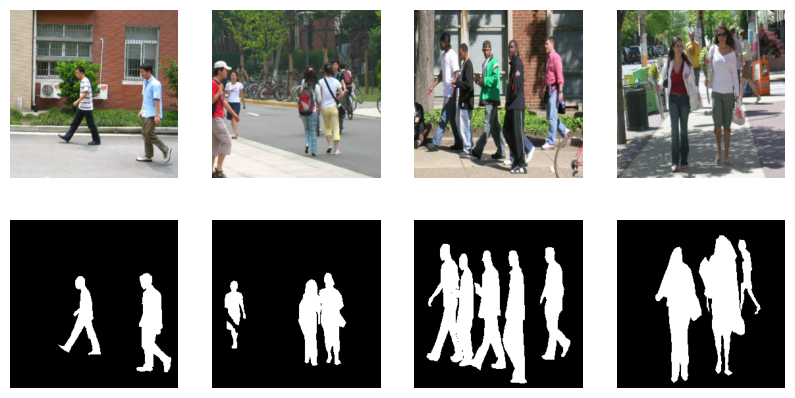

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for column, row in enumerate([0, 40, 80, 120]):
    axes[0, column].imshow(images[row])
    axes[1, column].imshow(masks[row], cmap="gray")
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.show()

## Tensor + split train / validasi

In [5]:
X = torch.tensor(images).permute(0, 3, 1, 2)
X = X.float() / 255
X = (X - MEAN) / STD
y = torch.tensor(masks)
train_rows, val_rows = train_test_split(np.arange(len(X)), test_size=0.2, random_state=SEED)
print("train:", len(train_rows), "| validasi:", len(val_rows))

train: 136 | validasi: 34


## Model
Pilih SATU blok model: hapus `#` di blok DeepLabV3, beri `#` pada blok LRASPP.

In [6]:
def make_model():
    net = segmentation.lraspp_mobilenet_v3_large(weights=None, weights_backbone=None,
                                                 num_classes=21)
    net.load_state_dict(torch.load(f"{PRETRAINED}/lraspp_mobilenet/model.pth",
                                   map_location="cpu"))
    net.classifier.low_classifier = nn.Conv2d(40, 2, 1)     # kepala baru: 2 kelas
    net.classifier.high_classifier = nn.Conv2d(128, 2, 1)
    # net = segmentation.deeplabv3_mobilenet_v3_large(weights=None, weights_backbone=None,
    #                                                 num_classes=21, aux_loss=True)
    # net.load_state_dict(torch.load(f"{PRETRAINED}/deeplabv3_mobilenet/model.pth",
    #                                map_location="cpu"))
    # net.classifier[4] = nn.Conv2d(256, 2, 1)
    return net.to(DEVICE)


print(type(make_model()).__name__)

LRASPP


## Latih (fine-tune semua lapisan)

In [7]:
def train_model(X_part, y_part):
    net = make_model()
    optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
    for epoch in range(EPOCHS):
        net.train()
        order = torch.randperm(len(X_part))
        for start in range(0, len(order), BATCH_SIZE):
            batch_rows = order[start:start + BATCH_SIZE]
            output = net(X_part[batch_rows].to(DEVICE))["out"]
            loss = functional.cross_entropy(output, y_part[batch_rows].to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print("epoch", epoch + 1, "loss", round(loss.item(), 4))
    return net


net = train_model(X[train_rows], y[train_rows])

epoch 1 loss 0.1805


epoch 2 loss 0.1307


epoch 3 loss 0.1063


epoch 4 loss 0.0912


epoch 5 loss 0.0808


## Evaluasi: IoU pejalan kaki per gambar di validasi
IoU = irisan / gabungan piksel prediksi dan piksel asli (1 = sama persis).

mean IoU (validasi): 0.656


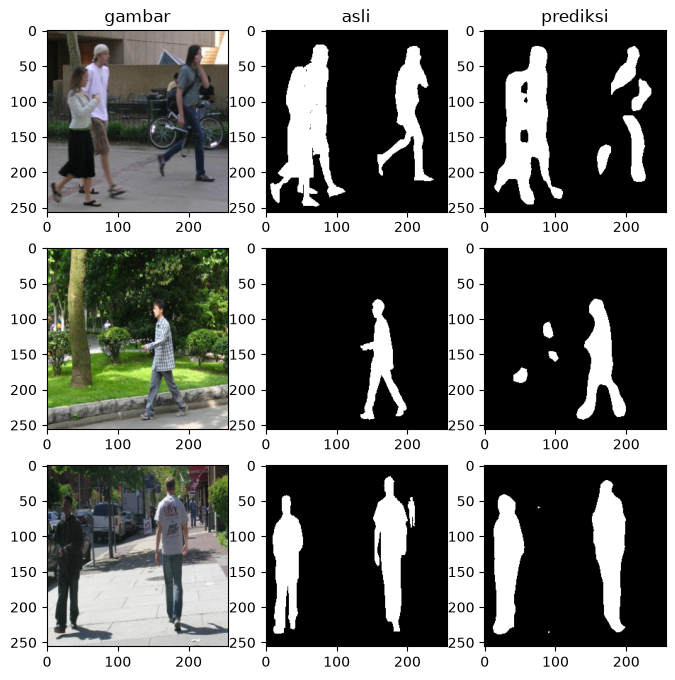

In [8]:
def predict_masks(net, X_part):
    net.eval()
    batches = []
    with torch.no_grad():
        for start in range(0, len(X_part), 16):
            output = net(X_part[start:start + 16].to(DEVICE))["out"]
            batches.append(output.argmax(1).cpu())
    return torch.cat(batches).numpy()


def iou_per_image(pred_masks, true_masks):
    intersection = ((pred_masks == 1) & (true_masks == 1)).sum(axis=(1, 2))
    union = ((pred_masks == 1) | (true_masks == 1)).sum(axis=(1, 2))
    return intersection / union


val_masks = predict_masks(net, X[val_rows])
val_iou = iou_per_image(val_masks, masks[val_rows])
print("mean IoU (validasi):", round(val_iou.mean(), 4))

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for number in range(3):
    axes[number, 0].imshow(images[val_rows[number]])
    axes[number, 1].imshow(masks[val_rows[number]], cmap="gray")
    axes[number, 2].imshow(val_masks[number], cmap="gray")
axes[0, 0].set_title("gambar")
axes[0, 1].set_title("asli")
axes[0, 2].set_title("prediksi")
plt.show()

## Latih ulang di semua data + hasil per gambar
Data demo tidak punya test, jadi IoU semua data dicatat di hasil.csv (hanya cek).

In [9]:
net = train_model(X, y)
all_iou = iou_per_image(predict_masks(net, X), masks)

file_names = []
for image_path in image_paths:
    file_names.append(os.path.basename(image_path))

result = pd.DataFrame()
result["file"] = file_names
result["iou"] = all_iou
result.to_csv("hasil.csv", index=False)
print("mean IoU (semua data, hanya cek):", round(all_iou.mean(), 4))
result.head()

epoch 1 loss 0.2535


epoch 2 loss 0.0966


epoch 3 loss 0.1329


epoch 4 loss 0.2237


epoch 5 loss 0.1077


mean IoU (semua data, hanya cek): 0.7574


,file,iou
0,FudanPed00001.png,0.785045
1,FudanPed00002.png,0.717152
2,FudanPed00003.png,0.774575
3,FudanPed00004.png,0.718003
4,FudanPed00005.png,0.798992
